# 国庆NumPy项目：康威生命游戏（参考答案）

> 请先独立完成任务书，卡住再看本文件。
> 参考：Nicolas Rougier《From Python to NumPy》、Jake VanderPlas 博客。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
plt.rcParams['animation.embed_limit']=2**128

## 1. 规则

网格中每个细胞 1=活，0=死，看周围8个邻居：
- 活细胞：邻居为 2 或 3 则继续活，否则死亡（孤独/拥挤）
- 死细胞：邻居恰好为 3 则复活

## 2. 造网格

In [2]:
np.random.seed(0)
def random_grid(h,w,p=0.3):
    return (np.random.random((h,w))<p).astype(np.int8)

def add_glider(g,i,j):
    g[i:i+3, j:j+3]=[[0,1,0],
                     [0,0,1],
                     [1,1,1]]
g=random_grid(10,10,0.3)
print(g)

[[0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 1 1 1 0 0 0]
 [0 0 0 0 1 0 1 0 0 0]
 [1 0 0 0 1 0 0 0 0 0]
 [0 0 0 1 0 0 1 1 0 0]
 [0 0 0 1 1 1 0 1 0 1]
 [1 1 0 1 1 0 0 1 0 1]
 [0 0 0 0 0 1 1 1 1 1]
 [0 0 1 0 0 1 0 1 0 0]
 [0 0 1 0 1 1 0 1 0 1]]


## 3. 计算8邻居数（核心）

### 方法A：np.roll 环形边界（简洁，边界与对边相连）
对网格在两个方向上滚动，把8个方向的网格加起来。

In [3]:
def neighbors(g):
    n=np.zeros_like(g,dtype=np.int8)
    for di in (-1,0,1):
        for dj in (-1,0,1):
            if di==0 and dj==0: continue
            n += np.roll(np.roll(g,di,axis=0), dj, axis=1)
    return n

test=np.zeros((6,6),dtype=np.int8)
add_glider(test,1,1)
print(neighbors(test))

[[0 1 1 1 0 0]
 [0 1 1 2 1 0]
 [1 3 5 3 2 0]
 [1 1 3 2 2 0]
 [1 2 3 2 1 0]
 [0 0 0 0 0 0]]


### 方法B：8切片 + 零边界（边界外当作0，不环形）

In [4]:
def neighbors_pad(g):
    P=np.pad(g,1)              # 外围补一圈0
    n=np.zeros_like(g,dtype=np.int8)
    for di in (0,1,2):
        for dj in (0,1,2):
            if di==1 and dj==1: continue
            n += P[di:di+g.shape[0], dj:dj+g.shape[1]]
    return n
print(np.array_equal(neighbors(test), neighbors_pad(test)))

True


## 4. 更新一代（核心）

In [5]:
def step(g):
    n=neighbors(g)
    alive=(g==1)&((n==2)|(n==3))   # 活且邻居2或3
    born=(g==0)&(n==3)            # 死且邻居3
    return (alive|born).astype(np.int8)

print("一代前人口:",test.sum())
t2=step(test)
print("一代后人口:",t2.sum())

一代前人口: 5
一代后人口: 5


## 5. 验证滑翔机会移动（4代后整体平移一格）

In [6]:
g0=np.zeros((8,8),dtype=np.int8); add_glider(g0,1,1)
g4=g0.copy()
for _ in range(4): g4=step(g4)
print("初始位置(1:4,1:4):"); print(g0[1:4,1:4])
print("4代后位置(2:5,2:5)，图案相同:"); print(g4[2:5,2:5])

初始位置(1:4,1:4):
[[0 1 0]
 [0 0 1]
 [1 1 1]]
4代后位置(2:5,2:5)，图案相同:
[[0 1 0]
 [0 0 1]
 [1 1 1]]


## 6. 动画

In [7]:
np.random.seed(1)
world=random_grid(40,40,0.25)
fig,ax=plt.subplots(figsize=(6,6)); ax.axis('off')
im=ax.imshow(world,cmap='binary')
def update(frame):
    global world
    world=step(world)
    im.set_data(world)
    return (im,)
ani=FuncAnimation(fig,update,frames=80,interval=120,blit=True)
plt.close()
HTML(ani.to_jshtml())

## 7. 人口曲线（观察稳定/振荡/灭绝）

C:\Users\千禧\AppData\Local\Temp\ipykernel_22148\725075866.py:6: UserWarning: Glyph 20195 (\N{CJK UNIFIED IDEOGRAPH-4EE3}) missing from font(s) DejaVu Sans.
  plt.title('人口变化'); plt.tight_layout(); plt.show()
C:\Users\千禧\AppData\Local\Temp\ipykernel_22148\725075866.py:6: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from font(s) DejaVu Sans.
  plt.title('人口变化'); plt.tight_layout(); plt.show()
C:\Users\千禧\AppData\Local\Temp\ipykernel_22148\725075866.py:6: UserWarning: Glyph 27963 (\N{CJK UNIFIED IDEOGRAPH-6D3B}) missing from font(s) DejaVu Sans.
  plt.title('人口变化'); plt.tight_layout(); plt.show()
C:\Users\千禧\AppData\Local\Temp\ipykernel_22148\725075866.py:6: UserWarning: Glyph 32454 (\N{CJK UNIFIED IDEOGRAPH-7EC6}) missing from font(s) DejaVu Sans.
  plt.title('人口变化'); plt.tight_layout(); plt.show()
C:\Users\千禧\AppData\Local\Temp\ipykernel_22148\725075866.py:6: UserWarning: Glyph 32990 (\N{CJK UNIFIED IDEOGRAPH-80DE}) missing from font(s) DejaVu Sans.
  plt.title('人口变化

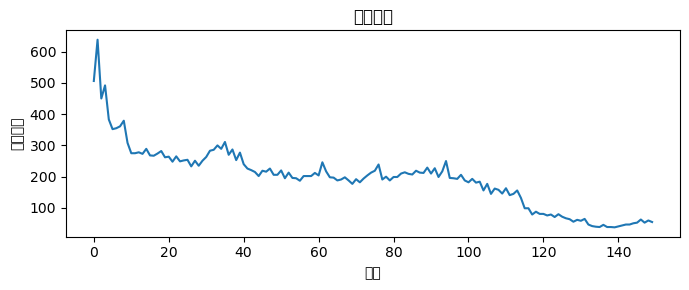

In [8]:
np.random.seed(2)
w=random_grid(40,40,0.3); pop=[]
for _ in range(150):
    pop.append(w.sum()); w=step(w)
plt.figure(figsize=(7,3)); plt.plot(pop); plt.xlabel('代数'); plt.ylabel('活细胞数')
plt.title('人口变化'); plt.tight_layout(); plt.show()

---
## 选做：Mandelbrot 分形（纯NumPy，视觉震撼）

复平面上每个点 c，从 z=0 反复 `z=z^2+c`，若 |z|>2 则逃逸。记录逃逸所需步数并成像。

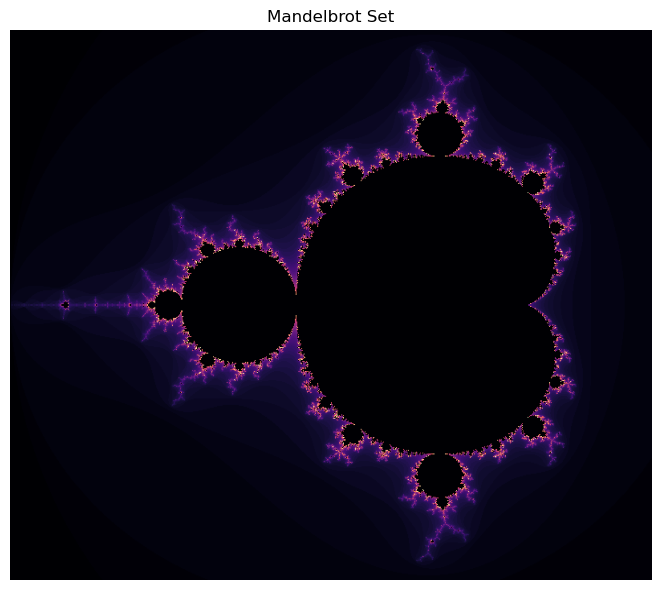

In [9]:
def mandelbrot(xmin,xmax,ymin,ymax,w=800,h=600,itermax=80):
    xs=np.linspace(xmin,xmax,w); ys=np.linspace(ymin,ymax,h)
    c=xs[None,:]+1j*ys[:,None]          # (h,w) 复数网格，用到广播
    z=np.zeros_like(c); count=np.zeros(c.shape,dtype=int)
    alive=np.ones(c.shape,dtype=bool)
    for k in range(itermax):
        z[alive]=z[alive]**2+c[alive]
        escaped=alive&(np.abs(z)>2)
        count[escaped]=k; alive[escaped]=False
    return count
M=mandelbrot(-2.0,0.8,-1.2,1.2)
plt.figure(figsize=(9,6)); plt.imshow(M,cmap='magma',extent=[-2,0.8,-1.2,1.2])
plt.axis('off'); plt.title('Mandelbrot Set'); plt.tight_layout(); plt.show()

## 函数速查

```python
np.roll(a, shift, axis)   # 循环平移（环形边界邻居）
np.pad(a, 1)              # 补零（零边界）
np.zeros_like / np.ones_like
FuncAnimation(fig, update, frames, interval, blit)
1j                        # Python虚数单位，构造复数网格
```